# A/B test: does moving the first gate from level 30 to 40 change retention?

**Data.** Cookie Cats mobile game experiment, 90,189 players randomised to `gate_30` (control) or `gate_40`. This module is independent of Olist. It exists to show experiment analysis, because Olist has no experiment data.

**Plan.** Two primary outcomes, day-1 and day-7 retention, so significance is judged at alpha = 0.025 (Bonferroni).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import json, os
import numpy as np, pandas as pd, psycopg2, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from scipy import stats
pd.set_option('display.width',140)
plt.rcParams.update({'figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'axes.axisbelow':True,'grid.color':'#e6e6e3','font.size':10})
INK,ACC,MUTE='#2b2b2b','#20808D','#9a9a94'
os.makedirs('../outputs/charts',exist_ok=True)
def save_metrics(key,val):
    p='../outputs/metrics.json'; m=json.load(open(p)) if os.path.exists(p) else {}
    m[key]=val; json.dump(m,open(p,'w'),indent=2,default=float)


In [2]:
d=pd.read_csv('../data/raw/cookie_cats.csv')
print(d.shape,'| nulls',d.isna().sum().sum(),'| duplicate users',d.userid.duplicated().sum())
g=d.groupby('version').agg(players=('userid','size'),d1_pct=('retention_1',lambda v:100*v.mean()),d7_pct=('retention_7',lambda v:100*v.mean()),median_rounds=('sum_gamerounds','median'),zero_rounds_pct=('sum_gamerounds',lambda v:100*(v==0).mean()),max_rounds=('sum_gamerounds','max')); display(g.round(2))
g.to_csv('../outputs/tables/ab_summary.csv')

(90189, 5) | nulls 0 | duplicate users 0


,players,d1_pct,d7_pct,median_rounds,zero_rounds_pct,max_rounds
version,,,,,,
gate_30,44700,44.82,19.02,17.0,4.33,49854
gate_40,45489,44.23,18.20,16.0,4.52,2640


## 1. Sample ratio check

This test assumes a 50/50 design, which the public data does not document. A 50/50 experiment should split close to 50/50. A failed check can signal a broken assignment or logging process, and it should be raised before any result is trusted.

In [3]:
n30=(d.version=='gate_30').sum(); srm=stats.chisquare([n30,len(d)-n30]).pvalue
print(f'gate_30 share: {100*n30/len(d):.2f}%  |  chi-square p = {srm:.4f}')
print('FLAG: below the usual 0.01 alarm threshold' if srm<.01 else 'OK')

gate_30 share: 49.56%  |  chi-square p = 0.0086
FLAG: below the usual 0.01 alarm threshold


If the design was 50/50, the split is off by under 1% and still fails the usual p < 0.01 alarm. The public data has no assignment logs, so the cause cannot be traced. The results below are reported with that warning attached, and a real team would investigate before shipping.

## 2. Outliers

One player logged 49,854 rounds, nearly 17 times the next highest. Retention is a yes/no outcome, so this cannot distort the main results. It would distort any mean-rounds comparison, so that comparison uses medians and a rank test.

In [4]:
rng=np.random.default_rng(42); out=[]; B=20000
for metric,label in [('retention_1','Day 1'),('retention_7','Day 7')]:
    a=d[d.version=='gate_40'][metric]; b=d[d.version=='gate_30'][metric]
    z,p=proportions_ztest([a.sum(),b.sum()],[len(a),len(b)])
    diff=a.mean()-b.mean(); boot=rng.binomial(len(a),a.mean(),B)/len(a)-rng.binomial(len(b),b.mean(),B)/len(b)
    out.append(dict(metric=label,gate_30_pct=100*b.mean(),gate_40_pct=100*a.mean(),diff_pts=100*diff,ci_low=100*np.percentile(boot,1.25),ci_high=100*np.percentile(boot,98.75),z=z,p_value=p,sig_at_0025=p<.025,prob_gate40_worse=(boot<0).mean()))
ab=pd.DataFrame(out); display(ab.round(4)); ab.to_csv('../outputs/tables/ab_results.csv',index=False)
print('Rounds, Mann-Whitney p:',round(stats.mannwhitneyu(d[d.version=='gate_30'].sum_gamerounds,d[d.version=='gate_40'].sum_gamerounds).pvalue,4))
save_metrics('ab',dict(srm_p=srm,gate30_share=100*n30/len(d),results=ab.to_dict('records')))

,metric,gate_30_pct,gate_40_pct,diff_pts,ci_low,ci_high,z,p_value,sig_at_0025,prob_gate40_worse
0,Day 1,44.8188,44.2283,-0.5905,-1.3326,0.1474,-1.7841,0.0744,False,0.9627
1,Day 7,19.0201,18.2000,-0.8201,-1.3885,-0.2410,-3.1644,0.0016,True,0.9996


Rounds, Mann-Whitney p: 0.0502


Intervals are 97.5%, matching the corrected alpha. Because the outcome is binary, resampling a group is equivalent to a binomial draw, which makes 20,000 replications instant.

## 3. Power

In [5]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize as es
pw=NormalIndPower()
for lab,base in [('Day 1',.4482),('Day 7',.1902)]:
    h=es(base,base-.005); print(lab,'n per group for a 0.5-point drop at 80% power, alpha .025:',int(pw.solve_power(h,power=.8,alpha=.025)))
    print('   Achieved power for that drop with ~45,000 per group:',round(pw.power(h,45000,.025),2))

Day 1 n per group for a 0.5-point drop at 80% power, alpha .025: 187857
   Achieved power for that drop with ~45,000 per group: 0.23
Day 7 n per group for a 0.5-point drop at 80% power, alpha .025: 115933
   Achieved power for that drop with ~45,000 per group: 0.37


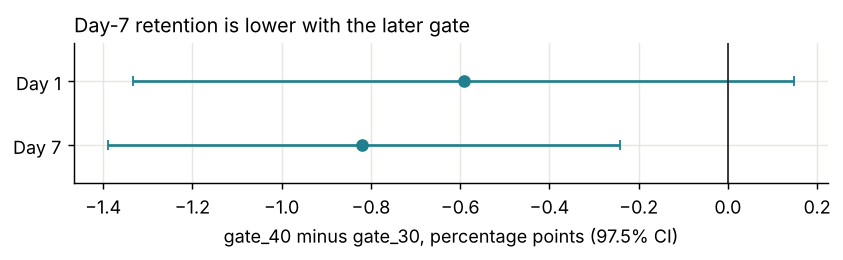

In [6]:
fig,ax=plt.subplots(figsize=(6.6,2.1)); y=[1,0]
ax.errorbar(ab.diff_pts,y,xerr=[ab.diff_pts-ab.ci_low,ab.ci_high-ab.diff_pts],fmt='o',color=ACC,capsize=3); ax.axvline(0,color=INK,lw=1)
ax.set_yticks(y); ax.set_yticklabels(ab.metric); ax.set_ylim(-.6,1.6); ax.set_xlabel('gate_40 minus gate_30, percentage points (97.5% CI)')
ax.set_title('Day-7 retention is lower with the later gate',loc='left',fontsize=11); plt.tight_layout(); plt.savefig('../outputs/charts/ab_result.png'); plt.show()

## Decision

Keep the gate at level 30. Day-7 retention is significantly lower at level 40 after correction. Day-1 retention is not significantly different, even before correction. Most players stop before level 30, which dilutes the measured effect, and filtering to players who reached the gate would bias the comparison because reaching it happens after assignment. The sample ratio warning should be investigated before treating the size of the effect as final.